# PS5: Facial Emotion Recognition using a CNN (FER-2013)
7 emotions: angry, disgust, fear, happy, neutral, sad, surprise (48x48 grayscale).

In [ ]:
import subprocess
import tensorflow as tf

MIN_FREE_VRAM_MB = 2048

gpus = tf.config.list_physical_devices('GPU')
if not gpus:
    print('=' * 66)
    print('GPU NOT FOUND - this notebook trains a CNN and needs a CUDA GPU.')
    print(f'Required: at least {MIN_FREE_VRAM_MB} MB of free VRAM.')
    print('Fix: Colab -> Runtime > Change runtime type > T4 GPU, then Run all.')
    print('     Local -> install NVIDIA driver + CUDA-enabled TensorFlow.')
    print('=' * 66)
    raise SystemExit('Stopped: no GPU available.')

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

free_mb = None
try:
    out = subprocess.check_output(
        ['nvidia-smi', '--query-gpu=memory.free', '--format=csv,noheader,nounits'],
        text=True, stderr=subprocess.DEVNULL)
    free_mb = max(int(v) for v in out.split())
except Exception:
    print('Note: nvidia-smi not available; skipping free-VRAM measurement.')

if free_mb is not None and free_mb < MIN_FREE_VRAM_MB:
    print('=' * 66)
    print(f'NOT ENOUGH FREE VRAM - found {free_mb} MB, need {MIN_FREE_VRAM_MB} MB.')
    print('Close other GPU programs/notebooks, restart the kernel, and run again.')
    print('=' * 66)
    raise SystemExit('Stopped: insufficient free VRAM.')

tf.keras.mixed_precision.set_global_policy('mixed_float16')
print('TensorFlow:', tf.__version__)
print('GPU:', gpus[0].name)
print('Free VRAM (MB):', free_mb if free_mb is not None else 'unknown')
print('Policy:', tf.keras.mixed_precision.global_policy().name)

TensorFlow: 2.21.0
GPU: /physical_device:GPU:0
Free VRAM (MB): 14910
Policy: mixed_float16


In [ ]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = None
IMG = (48, 48)
BATCH = 128
EPOCHS = 60
SEED = 42
keras.utils.set_random_seed(SEED)

In [ ]:
if DATA_DIR is None:
    try:
        import kagglehub
        DATA_DIR = kagglehub.dataset_download('msambare/fer2013')
    except Exception as exc:
        print('=' * 66)
        print('DATASET DOWNLOAD FAILED')
        print('Option 1: add a Kaggle API token (Colab Secrets: KAGGLE_API_TOKEN).')
        print('Option 2: download FER-2013 manually and set DATA_DIR in Cell 2.')
        print('Expected layout: DATA_DIR/train/<emotion>/*.jpg + DATA_DIR/test/<emotion>/*.jpg')
        print('=' * 66)
        raise SystemExit('Stopped: dataset not available.') from exc

train_dir = pathlib.Path(DATA_DIR) / 'train'
test_dir = pathlib.Path(DATA_DIR) / 'test'
if not train_dir.is_dir() or not test_dir.is_dir():
    raise SystemExit(f'Stopped: {DATA_DIR} must contain train/ and test/ folders.')
print('Dataset directory:', DATA_DIR)

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset directory: /kaggle/input/fer2013


In [ ]:
train_ds = keras.utils.image_dataset_from_directory(
    train_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
    label_mode='int', validation_split=0.1, subset='training', seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    train_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
    label_mode='int', validation_split=0.1, subset='validation', seed=SEED)
test_ds = keras.utils.image_dataset_from_directory(
    test_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
    label_mode='int', shuffle=False)
class_names = train_ds.class_names
num_classes = len(class_names)
print('Classes:', class_names)

train_ds = train_ds.cache()
val_ds = val_ds.cache()
test_ds = test_ds.cache()
y_train_all = np.concatenate([y.numpy() for _, y in train_ds])
weights = compute_class_weight('balanced', classes=np.arange(num_classes), y=y_train_all)
class_weight = dict(enumerate(weights))
print('Class weights:', {class_names[k]: round(float(v), 2) for k, v in class_weight.items()})

Found 28709 files belonging to 7 classes.
Using 25839 files for training.
Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Class weights: {'angry': 1.02, 'disgust': 9.3, 'fear': 1.01, 'happy': 0.57, 'neutral': 0.82, 'sad': 0.85, 'surprise': 1.31}


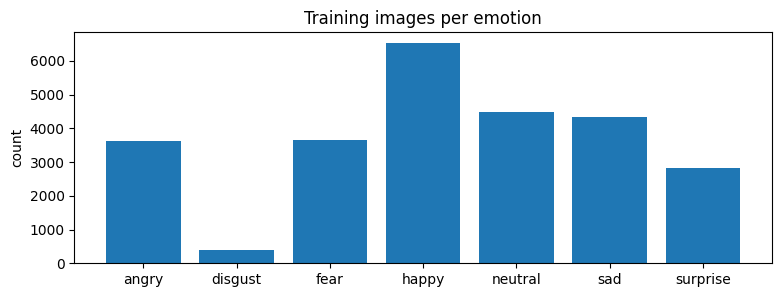

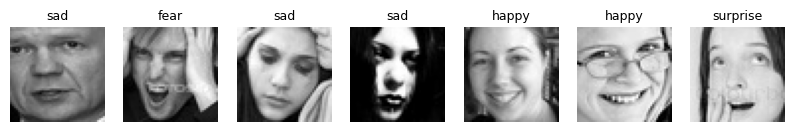

In [ ]:
counts = np.bincount(y_train_all, minlength=num_classes)
plt.figure(figsize=(9, 3))
plt.bar(class_names, counts)
plt.title('Training images per emotion')
plt.ylabel('count')
plt.show()

plt.figure(figsize=(10, 3))
for images, labels in train_ds.take(1):
    for i in range(7):
        plt.subplot(1, 7, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis('off')
plt.show()

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(2048, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

## Model

In [ ]:
model = keras.Sequential([
    layers.Input(IMG + (1,)),
    layers.Rescaling(1.0 / 255),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.Conv2D(32, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(32, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(64, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(64, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(128, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(256, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax', dtype='float32'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,470,247 (5.61 MB)

 Trainable params: 1,468,839 (5.60 MB)

 Non-trainable params: 1,408 (5.50 KB)

## Training

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint('best_emotion_cnn.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
]
history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    class_weight=class_weight, callbacks=callbacks, verbose=2)

Epoch 1/60
202/202 - 32s - 158ms/step - accuracy: 0.1878 - loss: 2.1432 - val_accuracy: 0.1871 - val_loss: 2.0419 - learning_rate: 0.0010
Epoch 2/60
202/202 - 9s - 43ms/step - accuracy: 0.2350 - loss: 1.9155 - val_accuracy: 0.2777 - val_loss: 1.8804 - learning_rate: 0.0010
Epoch 3/60
202/202 - 10s - 50ms/step - accuracy: 0.2849 - loss: 1.8040 - val_accuracy: 0.2007 - val_loss: 2.3557 - learning_rate: 0.0010
Epoch 4/60
202/202 - 9s - 46ms/step - accuracy: 0.3307 - loss: 1.7001 - val_accuracy: 0.3889 - val_loss: 1.5744 - learning_rate: 0.0010
Epoch 5/60
202/202 - 11s - 52ms/step - accuracy: 0.3725 - loss: 1.6044 - val_accuracy: 0.4063 - val_loss: 1.6049 - learning_rate: 0.0010
Epoch 6/60
202/202 - 9s - 44ms/step - accuracy: 0.4022 - loss: 1.5355 - val_accuracy: 0.4324 - val_loss: 1.4767 - learning_rate: 0.0010
Epoch 7/60
202/202 - 9s - 43ms/step - accuracy: 0.4230 - loss: 1.4862 - val_accuracy: 0.4282 - val_loss: 1.4565 - learning_rate: 0.0010
Epoch 8/60
202/202 - 9s - 44ms/step - accura

## Evaluation

Test accuracy: 0.6202   Test loss: 1.0084


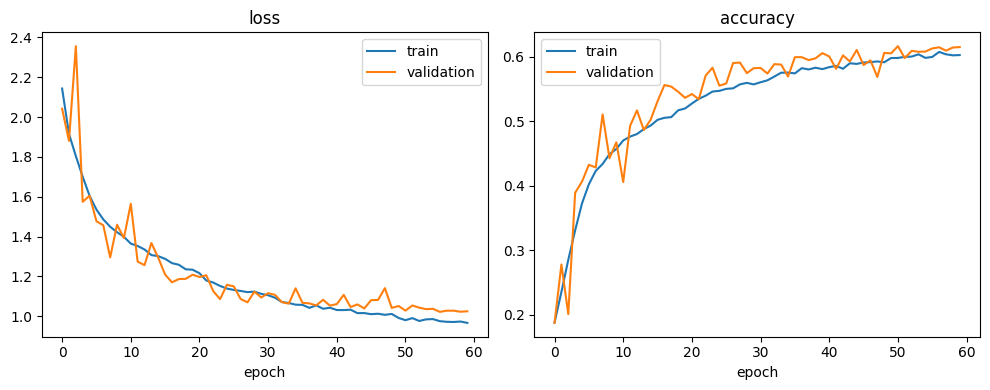

In [ ]:
loss, acc = model.evaluate(test_ds, verbose=0)
print(f'Test accuracy: {acc:.4f}   Test loss: {loss:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['loss', 'accuracy']):
    ax[i].plot(history.history[metric], label='train')
    ax[i].plot(history.history['val_' + metric], label='validation')
    ax[i].set_title(metric)
    ax[i].set_xlabel('epoch')
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       angry     0.5148    0.5459    0.5299       958
     disgust     0.3619    0.6847    0.4735       111
        fear     0.4937    0.3438    0.4053      1024
       happy     0.8638    0.8298    0.8465      1774
     neutral     0.5414    0.6261    0.5807      1233
         sad     0.5125    0.4779    0.4946      1247
    surprise     0.6987    0.7954    0.7440       831

    accuracy                         0.6202      7178
   macro avg     0.5695    0.6148    0.5821      7178
weighted avg     0.6211    0.6202    0.6169      7178



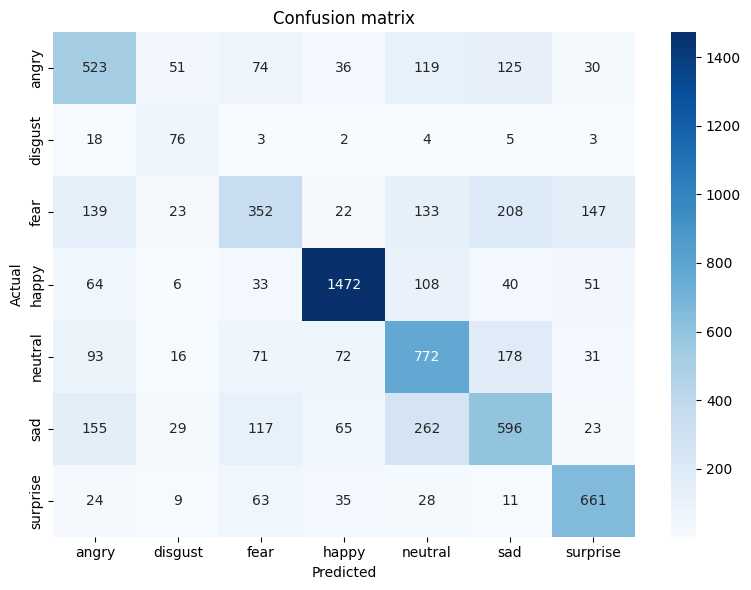

In [ ]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.tight_layout()
plt.show()

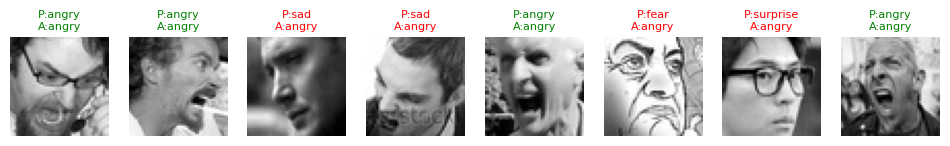

In [ ]:
plt.figure(figsize=(12, 3))
for images, labels in test_ds.take(1):
    probs = model.predict(images[:8], verbose=0)
    for i in range(8):
        plt.subplot(1, 8, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        p, t = int(probs[i].argmax()), int(labels[i])
        plt.title(f'P:{class_names[p]}\nA:{class_names[t]}', fontsize=8,
                  color='green' if p == t else 'red')
        plt.axis('off')
plt.show()

## Save and single-image inference

In [ ]:
model.save('emotion_cnn_final.keras')
print('Saved: best_emotion_cnn.keras and emotion_cnn_final.keras')


def predict_image(path):
    img = keras.utils.load_img(path, color_mode='grayscale', target_size=IMG)
    x = keras.utils.img_to_array(img)[None, ...]
    probs = model.predict(x, verbose=0)[0]
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title(f'{class_names[probs.argmax()]} ({probs.max():.1%})')
    plt.show()
    return dict(zip(class_names, probs.round(4)))

Saved: best_emotion_cnn.keras and emotion_cnn_final.keras
